# Step 0: Data collection 

1. **Define** the sector query: CPC/IPC codes + keywords in title/abstract, then **validate** it
2. **Extract** the tables needed by the next steps (tls201, tls224/209, tls206+tls207, tls212, tls202/203)
3. **Clean**: unit = DOCDB family, time = earliest filing year, harmonised applicants, flag the truncated years


**Contents**

1. Imports and macro variables
2. Search definitions (CPC, IPC, keywords)
3. Query functions
4. Running the queries
5. How much does each strategy contribute?
6. Validation of the query (sample for three LLM labellers, agreement, precision)
7. Extract
8. Clean

## 1. Imports and macro variables

In [1]:
from itertools import combinations
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import and_, distinct, func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # applications
    TLS202_APPLN_TITLE,         # titles
    TLS203_APPLN_ABSTR,         # abstracts
    TLS206_PERSON,              # persons (applicants and inventors)
    TLS207_PERS_APPLN,          # person <-> application links
    TLS209_APPLN_IPC,           # IPC classification
    TLS211_PAT_PUBLN,           # publications (bridge application -> citations)
    TLS212_CITATION,            # citations
    TLS224_APPLN_CPC,           # CPC classification
)

In [2]:
ENV = "PROD"                        # TEST while developing, PROD for the final numbers
START_YEAR, END_YEAR = 1990, 2023   # earliest filing year of the family (the EPO report starts in 1990)
IPR_TYPE = "PI"                     # patented inventions, excludes utility models
TRUNCATION_YEARS = 3                # last ~3 years are incomplete (18-month publication lag): flag, do not drop
INCLUDE_BROAD = False               # also match "quantum simulation" (a separate EPO report, see section 2)
RANDOM_STATE = 42
CHUNK = 5000                        # a too long IN (...) makes the query too large

OUTPUT_DIR = Path("outputs/step0")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
patstat = PatstatClient(env=ENV)
db = patstat.orm()

patstat.list_global_tables()

['tls201_appln',
 'tls204_appln_prior',
 'tls205_tech_rel',
 'tls216_appln_contn',
 'tls209_appln_ipc',
 'tls210_appln_n_cls',
 'tls222_appln_jp_class',
 'tls224_appln_cpc',
 'tls225_docdb_fam_cpc',
 'tls228_docdb_fam_citn',
 'tls231_inpadoc_legal_event',
 'tls211_pat_publn',
 'tls212_citation',
 'tls214_npl_publn',
 'tls215_citn_categ',
 'tls206_person',
 'tls207_pers_appln',
 'tls226_person_orig',
 'tls227_pers_publn',
 'tls801_country',
 'tls803_legal_event_code',
 'tls901_techn_field_ipc',
 'tls902_ipc_nace2',
 'tls904_nuts',
 'tls229_appln_nace2',
 'tls230_appln_techn_field',
 'tls202_appln_title',
 'tls203_appln_abstr']

## 2. Search definitions

### 2.1 Classification codes
- **IPC**: `G06N 10/00` exists only since 2019 (EPO report, Box 1), so this strategy is thin for older families. `G06N99/002` is the pre-2019 place of "quantum computers".
- **CPC**: a QC subdivision exists since the creation of the CPC (inherited from ECLA); `Y10S977/933` is the old nanotechnology collection "spintronics or quantum computing".

Neighbouring codes (`H04L9/0852` QKD, `H04B10/70` quantum communication, `B82Y10/00`, superconducting-device classes) are **not** used alone: quantum communication is a separate EPO report and these classes are too broad without quantum text.

In [4]:
IPC_CODES = (
    "G06N10/",
    "G06N99/002",
)

CPC_CODES = (
    "G06N10/",
    "G06N99/002",
    "Y10S977/933",
)

### 2.2 Keywords as regex

`within(a, b, n)` = `a` and `b` in any order with at most `n` words in between (EPO `nD`).
Terms that look quantum but are not QC (*post-quantum* cryptography, *quantum-inspired* classical algorithms) are removed from the text **before** matching.

In [5]:
SEP = "[^a-z0-9]+"                   # anything between two words
QUBIT = "qu[ -]?(b|d|tr)its?"        # qubit, qu-bit, qudit, qutrit


def within(a, b, n):
    # a and b in any order, at most n words in between
    gap = f"({SEP}[a-z0-9]+){{0,{n}}}{SEP}"
    return f"({a}{gap}{b}|{b}{gap}{a})"


def word_regex(patterns):
    # whole-word match of any pattern
    return "(^|[^a-z0-9])(" + "|".join(patterns) + ")([^a-z0-9]|$)"

In [6]:
QC_PATTERNS = {
    "general": [
        "quantum[ -]+comput[a-z]*",                  # computer, computing, computation
        "quantum[ -]+information[ -]+process[a-z]*",
        "quantum[ -]+processors?",
        "quantum[ -]+processing[ -]+(unit|device|apparatus|system)s?",
        "quantum[ -]+chips?",
    ],
    "qubits_gates_circuits": [
        QUBIT,
        "quantum[ -]+bits?",
        "quantum[ -]+registers?",
        "quantum[ -]+bus(es)?",
        "(photon[a-z]*|flux|charge|phase)[ -]+" + QUBIT,
        within("quantum", "(gate|circuit)s?", 1),
        within(QUBIT, "control[a-z]*", 2),
        within(QUBIT, "couplers?", 1),
    ],
    "algorithms": [
        "quantum[ -]+algorithms?",
        "quantum[ -]+anneal[a-z]*",
        "quantum[ -]+optimi[sz][a-z]*",
        "quantum[ -]+machine[ -]+learning",
        "quantum[ -]+neural[ -]+network[a-z]*",
        "quantum[ -]+fourier[ -]+transform[a-z]*",
        "quantum[ -]+phase[ -]+estimation",
        "quantum[ -]+approximate[ -]+optimi[sz][a-z]*",
        "variational[ -]+quantum[ -]+(eigen[ -]?solver|algorithm|circuit)s?",
        within("quantum", "(shor|grover)'?s?", 4),
        "qaoa",
    ],
    "error_correction": [
        "quantum[ -]+error[ -]+(correct|detect|mitigat)[a-z]*",
        within("quantum", "fault[ -]+toleran[a-z]*", 3),
        within("quantum", "surface[ -]+codes?", 5),
    ],
    "software_and_hardware": [
        "quantum[ -]+(programming|software|compiler|assembler|instruction|kernel)s?",
        "quantum[ -]+(random[ -]+access[ -]+memor(y|ies)|ram)",
        "(topological|adiabatic)[ -]+quantum",
        "(trans|flux)[ -]?mons?",
        "nisq",
        "noisy[ -]+intermediate[ -]+scale[ -]+quantum",
        "qiskit",
    ],
}

# quantum simulation is a separate EPO report, so it is optional
BROAD_PATTERNS = [
    "quantum[ -]+simulat[a-z]*",
]

# removed from the text before matching
NEGATIVE_PATTERNS = [
    "post[ -]?quantum",                                          # post-quantum cryptography
    "quantum[ -]+inspired",                                      # classical algorithms
    "quantum[ -]+(behaved|behaviou?red)",                        # quantum-behaved particle swarm
    "quantum[ -]+(particle[ -]+swarm|genetic|evolutionary)",
]

# cheap LIKE prefilter: every pattern above contains one of these strings
ANCHORS = (
    "quantum", "qubit", "qu-bit", "qu bit", "qudit", "qutrit",
    "qaoa", "qiskit", "nisq", "transmon", "fluxmon", "trans-mon", "flux-mon", "trans mon", "flux mon",
)

patterns = [p for group in QC_PATTERNS.values() for p in group]
if INCLUDE_BROAD:
    patterns += BROAD_PATTERNS

QC_REGEX = word_regex(patterns)
NEGATIVE_REGEX = word_regex(NEGATIVE_PATTERNS)

## 3. Query functions

Every query goes through `in_scope()` (family, IP right type, time window) and returns **one row per family**, because the unit of analysis is the DOCDB family.

'TEXT' is title + abstract in lower case. PATSTAT keeps one abstract per application, in the language of the document, so the English-only filter is applied later, only where it matters (section 6).

In [7]:
FAMILY_COLUMNS = (
    TLS201_APPLN.docdb_family_id,
    TLS201_APPLN.earliest_filing_year,
    TLS201_APPLN.docdb_family_size,
)

TEXT = func.lower(
    func.concat(
        func.coalesce(TLS202_APPLN_TITLE.appln_title, ""),
        " ",
        func.coalesce(TLS203_APPLN_ABSTR.appln_abstract, ""),
    )
)


def in_scope(query):
    # applications that belong to a family, of the chosen IP right type, in the time window
    return query.filter(
        TLS201_APPLN.docdb_family_id > 0,
        TLS201_APPLN.earliest_filing_year.between(START_YEAR, END_YEAR),
        TLS201_APPLN.ipr_type == IPR_TYPE,
    )


def symbol_prefix_condition(symbol_column, codes):
    # OR-condition: the blank-stripped classification symbol starts with one of the codes
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


def keyword_condition():
    # cheap LIKE prefilter, then the regex on the text without the false friends
    text_clean = func.regexp_replace(TEXT, NEGATIVE_REGEX, " ")
    return and_(
        or_(*(TEXT.like(f"%{a}%") for a in ANCHORS)),
        func.regexp_contains(text_clean, QC_REGEX),
    )


def query_by_keywords(*columns):
    return in_scope(
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition())
    )


def query_by_ipc(*columns):
    return in_scope(
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .join(TLS209_APPLN_IPC, TLS201_APPLN.appln_id == TLS209_APPLN_IPC.appln_id)
        .filter(symbol_prefix_condition(TLS209_APPLN_IPC.ipc_class_symbol, IPC_CODES))
    )


def query_by_cpc(*columns):
    return in_scope(
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, CPC_CODES))
    )

## 4. Running the queries

4 different queries:
1) IPC
2) cpc
3) keyword
4) hybrid

In [8]:
q_ipc = query_by_ipc(*FAMILY_COLUMNS).distinct()

df_ipc = patstat.df(q_ipc)
df_ipc.head()


,docdb_family_id,earliest_filing_year,docdb_family_size
0,92866156,2023,1
1,68468736,2019,3
2,68614702,2018,4
3,78086110,2020,7
4,86936966,2023,1


In [9]:
q_cpc = query_by_cpc(*FAMILY_COLUMNS).distinct()

df_cpc = patstat.df(q_cpc)
df_cpc.head()

,docdb_family_id,earliest_filing_year,docdb_family_size
0,70052520,2018,4
1,73043082,2020,13
2,81454653,2020,7
3,89578363,2022,2
4,41434498,2008,8


In [10]:
q_keywords = query_by_keywords(*FAMILY_COLUMNS).distinct()

df_keywords = patstat.df(q_keywords)
df_keywords.head()

,docdb_family_id,earliest_filing_year,docdb_family_size
0,78819349,2021,2
1,89984896,2022,4
2,74569911,2020,11
3,88600422,2023,5
4,89947711,2023,1


In [11]:
print(f"IPC: {df_ipc['docdb_family_id'].nunique():,} | CPC: {df_cpc['docdb_family_id'].nunique():,} | "
      f"keywords: {df_keywords['docdb_family_id'].nunique():,} families")

IPC: 9,572 | CPC: 8,676 | keywords: 9,676 families


**Hybrid** QC = keywords **OR** IPC **OR** CPC: a `UNION` of the three sets of family ids, joined back to the applications for the family attributes.

In [12]:
family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")

hybrid_ids = (
    query_by_keywords(family_id)
    .union(query_by_ipc(family_id), query_by_cpc(family_id))
    .subquery()
)

q_hybrid = (
    db.query(*FAMILY_COLUMNS)
    .select_from(TLS201_APPLN)
    .join(hybrid_ids, TLS201_APPLN.docdb_family_id == hybrid_ids.c.docdb_family_id)
    .distinct()
)

df_hybrid = patstat.df(q_hybrid)
print(f"Hybrid QC set: {df_hybrid['docdb_family_id'].nunique():,} families")
df_hybrid.head()

Hybrid QC set: 12,833 families


,docdb_family_id,earliest_filing_year,docdb_family_size
0,88124091,2023,1
1,86058511,2021,3
2,61779713,2017,3
3,84103988,2021,2
4,86229470,2021,3


## 5. How much does each strategy contribute?

In [13]:
ids = {
    "IPC": set(df_ipc["docdb_family_id"]),
    "CPC": set(df_cpc["docdb_family_id"]),
    "KW": set(df_keywords["docdb_family_id"]),
}

combos = {}
for r in (1, 2, 3):
    for names in combinations(ids, r):
        combos[" + ".join(names)] = set.union(*(ids[n] for n in names))
combos["IPC & CPC & KW (all agree)"] = set.intersection(*ids.values())

pd.Series({name: len(s) for name, s in combos.items()}, name="families")

IPC                            9572
CPC                            8676
KW                             9676
IPC + CPC                     10079
IPC + KW                      12452
CPC + KW                      12085
IPC + CPC + KW                12833
IPC & CPC & KW (all agree)     6141
Name: families, dtype: int64

In [14]:
# one row per family, with the strategies that found it
membership = (
    df_hybrid.groupby("docdb_family_id", as_index=False)
    .agg(earliest_filing_year=("earliest_filing_year", "min"), docdb_family_size=("docdb_family_size", "max"))
    .set_index("docdb_family_id")
)
for name, s in ids.items():
    membership[name] = membership.index.isin(s)

membership["classified"] = membership["IPC"] | membership["CPC"]
membership["evidence"] = np.select(
    [membership["classified"] & membership["KW"], membership["classified"]],
    ["class + keywords", "class only"],
    default="keywords only",
)

display(membership.groupby(["IPC", "CPC", "KW"]).size().rename("families").reset_index())

membership.reset_index().to_csv(OUTPUT_DIR / f"qc_families_{ENV}.csv", index=False)   # input of the next steps

,IPC,CPC,KW,families
0,False,False,True,2754
1,False,True,False,381
2,False,True,True,126
3,True,False,False,748
4,True,False,True,655
5,True,True,False,2028
6,True,True,True,6141


## 6. Validation of the query: sample of 100 families for three LLM labellers

Procedure (professor): draw **100 random families** from the query result, have **Claude, Gemini and ChatGPT** label each one blind (1 = quantum computing, 0 = not), and use the labels to judge the query.

1. **6.1-6.2** build the sample and write **one CSV for the LLMs** (`item, title, abstract`, no query information) and the prompt.
2. **By hand**: in a new chat of each LLM, attach the CSV, paste the prompt, download the answer as `labels_<llm>.csv` and save the three files in `outputs/step0/validation/labels/`.
3. **6.3-6.6** load the labels into a `100 x 3` DataFrame of 0/1 flags (index = `docdb_family_id`) and analyse it: how each LLM behaves, how their "yes" sets overlap (as we did for IPC / CPC / keywords), and the precision of the query.

**Reproducibility.** The sample is drawn with a fixed `random_state` from the families **sorted by id** and saved to `validation_key.csv` the first time; if the file exists it is **re-used, never redrawn**, so the three label files always refer to the same 100 families.

### 6.1 Sample (saved once)

In [15]:
def family_texts(family_ids, chunk=CHUNK):
    # one application per family: prefer English abstract, then any abstract, then the earliest filing
    frames = []
    for i in range(0, len(family_ids), chunk):
        q = (
            db.query(
                TLS201_APPLN.docdb_family_id, TLS201_APPLN.appln_id, TLS201_APPLN.appln_filing_date,
                TLS202_APPLN_TITLE.appln_title, TLS203_APPLN_ABSTR.appln_abstract, TLS203_APPLN_ABSTR.appln_abstract_lg,
            )
            .select_from(TLS201_APPLN)
            .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
            .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
            .filter(TLS201_APPLN.docdb_family_id.in_(family_ids[i:i + chunk]))
            .filter(or_(TLS202_APPLN_TITLE.appln_title.isnot(None), TLS203_APPLN_ABSTR.appln_abstract.isnot(None)))
        )
        frames.append(patstat.df(q))
    df = pd.concat(frames, ignore_index=True)
    df["en_abs"] = (df["appln_abstract_lg"] == "en") & df["appln_abstract"].notna()
    df["any_abs"] = df["appln_abstract"].notna()
    return (
        df.sort_values(["docdb_family_id", "en_abs", "any_abs", "appln_filing_date", "appln_id"],
                       ascending=[True, False, False, True, True])
        .drop_duplicates("docdb_family_id")[["docdb_family_id", "appln_title", "appln_abstract"]]
    )


# title + abstract of EVERY family of the query: used here (validation) and in section 7 (NLP)
FAMILY_IDS = sorted(int(i) for i in membership.index)
texts_all = family_texts(FAMILY_IDS)
texts_all[["appln_title", "appln_abstract"]] = texts_all[["appln_title", "appln_abstract"]].fillna("")

has_text = texts_all[(texts_all["appln_title"].str.strip() != "") | (texts_all["appln_abstract"].str.strip() != "")]["docdb_family_id"]
print(f"families with a title or an abstract: {len(has_text):,} / {len(FAMILY_IDS):,}")

families with a title or an abstract: 12,833 / 12,833


In [16]:
VAL_DIR = Path("outputs/step0/validation")
LABELS_DIR = VAL_DIR / "labels"
LABELS_DIR.mkdir(parents=True, exist_ok=True)
KEY_FILE = VAL_DIR / "validation_key.csv"          # family id + evidence + title/abstract (never shown to the LLMs)
LLM_FILE = VAL_DIR / "validation_for_llm.csv"      # item, title, abstract
SAMPLE_SIZE, MAX_ABSTRACT_CHARS = 100, 1500
LLM_NAMES = ("claude", "gemini", "chatgpt")

# sampling population: query families with some text (an LLM cannot label an empty record)
pool = membership.reset_index()[["docdb_family_id", "IPC", "CPC", "KW", "evidence"]]
pool = pool[pool["docdb_family_id"].isin(has_text)].sort_values("docdb_family_id")

if KEY_FILE.exists():
    sample = pd.read_csv(KEY_FILE)
    stale = ~sample["docdb_family_id"].isin(pool["docdb_family_id"])
    if stale.any():
        raise ValueError(f"{stale.sum()} families of {KEY_FILE} are not in the current query (or have no text): the sample is out of date. "
                         "If the LLM labelling has NOT started, delete the file and re-run this cell; otherwise check what changed in Step 0.")
    print(f"Sample re-used from {KEY_FILE}")
else:
    sample = pool.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)
    sample["item"] = sample.index + 1
    sample = sample.merge(texts_all, on="docdb_family_id", how="left")
    sample.to_csv(KEY_FILE, index=False)
    print(f"New sample saved to {KEY_FILE}")

sample[["appln_title", "appln_abstract"]] = sample[["appln_title", "appln_abstract"]].fillna("")
sample[["IPC", "CPC", "KW"]] = sample[["IPC", "CPC", "KW"]].astype(bool)
sample[["item", "docdb_family_id"]].to_csv(VAL_DIR / "sample_ids.csv", index=False)   # ids only: safe to commit
print(len(sample), "families |", sample["evidence"].value_counts().to_dict())

Sample re-used from outputs/step0/validation/validation_key.csv
100 families | {'class + keywords': 50, 'class only': 27, 'keywords only': 23}


### 6.2 File and prompt for the LLMs

The file has only `item` (1-100), `title` and `abstract`: **no family id and no evidence**, so the LLMs label blind. The `item` column is there so that each answer can be matched to its row even if an LLM skips or reorders a line. Edit `PROMPT` if the scope of Step 0 differs (same definition for the three LLMs, and the same one you would give a human).

In [17]:
PROMPT = """You are a patent analyst. The attached CSV has 100 patent families with columns: item, title, abstract.
For EACH row decide whether the invention is about QUANTUM COMPUTING.

Label 1 = quantum computing: quantum computers or processors, qubits (hardware, control, readout, coupling, fabrication for quantum information processing), quantum gates or circuits, quantum algorithms, quantum error correction, quantum software or compilers, quantum annealing, quantum machine learning run on quantum hardware.
Label 0 = anything else, including: quantum communication, quantum cryptography and quantum key distribution; quantum sensing and metrology; quantum dots or quantum wells in classical devices (lasers, LEDs, displays, solar cells); post-quantum cryptography; quantum-inspired algorithms run on classical computers; and patents unrelated to quantum.

Return a downloadable CSV file with exactly two columns, header `item,label`, and exactly 100 rows (one per input row, same order, item = the item of the input row). The label is 1 or 0. No other columns, no explanations."""

for_llm = sample[["item", "appln_title", "appln_abstract"]].rename(columns={"appln_title": "title", "appln_abstract": "abstract"})
for_llm["abstract"] = for_llm["abstract"].str.slice(0, MAX_ABSTRACT_CHARS)
for_llm.to_csv(LLM_FILE, index=False)
(VAL_DIR / "prompt.txt").write_text(PROMPT, encoding="utf-8")
print(f"Attach {LLM_FILE} and paste the prompt ({VAL_DIR / 'prompt.txt'}) in a NEW chat of each LLM.")
print("Save the answers as:", *[str(LABELS_DIR / f"labels_{n}.csv") for n in LLM_NAMES], sep="\n  ")

Attach outputs/step0/validation/validation_for_llm.csv and paste the prompt (outputs/step0/validation/prompt.txt) in a NEW chat of each LLM.
Save the answers as:
  outputs/step0/validation/labels/labels_claude.csv
  outputs/step0/validation/labels/labels_gemini.csv
  outputs/step0/validation/labels/labels_chatgpt.csv


*Practical notes.* If an LLM cuts the answer or the quality drops on 100 rows, send the file in two halves (items 1-50 and 51-100) and concatenate the two answers into one `labels_<llm>.csv`. Always **open the three files** and check the row count: LLMs sometimes miscount.

### 6.3 Load the three label files

Result: `labels`, a `100 x 3` DataFrame of 0/1 flags (one column per LLM, index = `docdb_family_id`). The loader accepts `item,label` files (matched by item) or a bare one-column file (matched by row position, which must then have exactly 100 rows), and stops with a clear message on missing or non-0/1 values.

In [18]:
def load_labels(path, items):
    df = pd.read_csv(path)
    df.columns = [str(c).strip().lower() for c in df.columns]
    label_col = "label" if "label" in df.columns else df.columns[-1]
    values = pd.to_numeric(df[label_col], errors="coerce")
    if "item" in df.columns:
        s = pd.Series(values.values, index=pd.to_numeric(df["item"], errors="coerce"))
        if s.index.duplicated().any():
            raise ValueError(f"{path.name}: duplicated items")
    else:
        if len(df) != len(items):
            raise ValueError(f"{path.name}: {len(df)} rows, expected {len(items)} (no 'item' column to match them)")
        s = pd.Series(values.values, index=items)
    return s.reindex(items)


missing_files = [str(LABELS_DIR / f"labels_{n}.csv") for n in LLM_NAMES if not (LABELS_DIR / f"labels_{n}.csv").exists()]
if missing_files:
    raise FileNotFoundError("Label files not found: " + ", ".join(missing_files) + ". Do the manual labelling (6.2) first.")

items = sample["item"].tolist()
labels = pd.DataFrame({n: load_labels(LABELS_DIR / f"labels_{n}.csv", items) for n in LLM_NAMES})

invalid = labels[labels.isna().any(axis=1) | ~labels.isin([0, 1]).all(axis=1)]
if len(invalid):
    raise ValueError(f"missing or non-0/1 labels for items {invalid.index.tolist()}")

labels = labels.astype(int)
labels.index = pd.Index(sample["docdb_family_id"].values, name="docdb_family_id")
names = list(labels.columns)
print(labels.shape)
labels.head()

(100, 3)


,claude,gemini,chatgpt
docdb_family_id,,,
60937925,1,1,1
89124015,1,1,1
90192225,0,0,0
91480062,1,1,1
79740096,1,1,1


### 6.4 How does each LLM behave?

One row per LLM:

- **share labelled 1**: how many of the 100 families it calls quantum computing (a labeller that is much more generous or stricter than the others stands out);
- **agrees with the other two (when they agree)**: take the families on which the *other two* LLMs give the same label, and check how often this LLM gives that label too (a low value flags an outlier labeller);
- **n families where the other two agree**: the base of the previous column.

In [19]:
rows = {}
for n in names:
    others = [m for m in names if m != n]
    unanimous = labels[others].nunique(axis=1) == 1
    rows[n] = {
        "share labelled 1": labels[n].mean(),
        "agrees with the other two (when they agree)": (labels.loc[unanimous, n] == labels.loc[unanimous, others[0]]).mean(),
        "n families where the other two agree": int(unanimous.sum()),
    }

display(pd.DataFrame(rows).T.style.format({
    "share labelled 1": "{:.1%}",
    "agrees with the other two (when they agree)": "{:.1%}",
    "n families where the other two agree": "{:.0f}",
}))

,share labelled 1,agrees with the other two (when they agree),n families where the other two agree
claude,62.0%,95.3%,85
gemini,62.0%,93.1%,87
chatgpt,55.0%,90.0%,90


### 6.5 How do their "yes" sets overlap? (same logic as IPC / CPC / keywords in section 5)

Each LLM defines a set of families (those it labels 1). As for the three queries: size of each set, of their intersections and unions, and the **vote pattern** of every family (who said yes). The patterns with a single dissenter show which LLM is the outlier; the patterns `111` and `000` are the safe cases.

claude                         62
gemini                         62
chatgpt                        55
claude ∩ gemini                57
claude ∩ chatgpt               52
gemini ∩ chatgpt               51
claude ∩ gemini ∩ chatgpt      50
at least 1 says 1 (union)      69
at least 2 say 1 (majority)    60
Name: families, dtype: int64

Jaccard similarity of the 'yes' sets:


,claude,gemini,chatgpt
claude,1.00,0.85,0.80
gemini,0.85,1.00,0.77
chatgpt,0.80,0.77,1.00


claude+gemini+chatgpt    50
nobody                   31
claude+gemini             7
gemini                    4
claude                    3
chatgpt                   2
claude+chatgpt            2
gemini+chatgpt            1
Name: families, dtype: int64

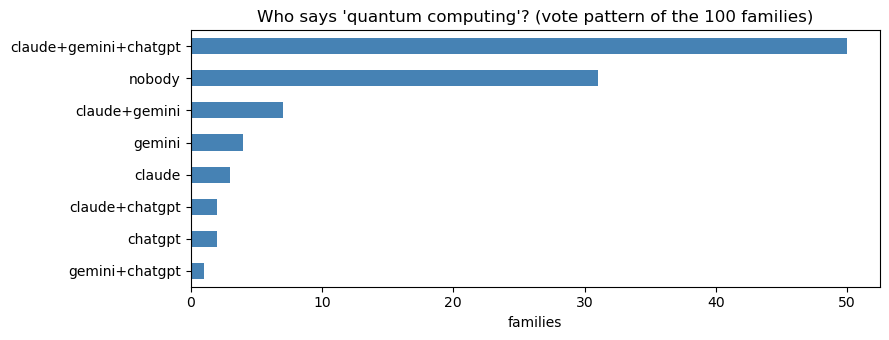

In [20]:
yes = {n: set(labels.index[labels[n] == 1]) for n in names}

overlap = {}
for r in (1, 2, 3):
    for combo in combinations(names, r):
        overlap[" ∩ ".join(combo)] = len(set.intersection(*(yes[n] for n in combo)))     # all of these say 1
overlap["at least 1 says 1 (union)"] = len(set.union(*yes.values()))
overlap["at least 2 say 1 (majority)"] = int((labels.sum(axis=1) >= 2).sum())
display(pd.Series(overlap, name="families"))

jaccard = pd.DataFrame({a: {b: len(yes[a] & yes[b]) / len(yes[a] | yes[b]) for b in names} for a in names})
print("Jaccard similarity of the 'yes' sets:")
display(jaccard.round(2))

pattern = labels.apply(lambda r: "+".join(n for n in names if r[n] == 1) or "nobody", axis=1)
pattern_counts = pattern.value_counts().rename("families")
display(pattern_counts)

fig, ax = plt.subplots(figsize=(9, 3.5))
pattern_counts.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set(title="Who says 'quantum computing'? (vote pattern of the 100 families)", xlabel="families")
plt.tight_layout()
plt.show()

### 6.6 Precision of the query

**Precision** = share of the families selected by the query that really are quantum computing. The reference label is the **majority vote** (at least 2 of the 3 LLMs say 1). Every precision comes with a **95% Wilson interval** (suited to a proportion on a small sample; with n = 100 it is wide, roughly ±10 points).

The cell produces:

1. **Precision table**: the whole query; each strategy (families found by IPC, by CPC, by keywords; these rows overlap, a family found by two strategies is in both); and the three evidence groups of section 5 (`class + keywords`, `class only`, `keywords only`, which do not overlap). The evidence groups say *where* the noise comes from; they have few families each, so read them as indicative.
2. **Bounds**: precision under a *strict* rule (all three say 1), a *lenient* rule (at least one says 1) and with each LLM alone, to show how much the answer depends on who labels.
3. **Estimated number of true quantum-computing families**: precision x the number of families the sample was drawn from, with its interval (valid because the sample is random).
4. **Figure**: the precision table with its intervals.

,sample,QC (majority),precision,CI low,CI high
group,,,,,
whole query,100,60,60.0%,50.2%,69.1%
found by IPC,73,54,74.0%,62.9%,82.7%
found by CPC,70,49,70.0%,58.5%,79.5%
found by KW,73,53,72.6%,61.4%,81.5%
class + keywords,50,47,94.0%,83.8%,97.9%
class only,27,7,25.9%,13.2%,44.7%
keywords only,23,6,26.1%,12.5%,46.5%


,sample,QC (majority),precision,CI low,CI high
group,,,,,
majority (reference),100,60,60.0%,50.2%,69.1%
strict: all 3 say 1,100,50,50.0%,40.4%,59.6%
lenient: at least 1 says 1,100,69,69.0%,59.4%,77.2%
claude alone,100,62,62.0%,52.2%,70.9%
gemini alone,100,62,62.0%,52.2%,70.9%
chatgpt alone,100,55,55.0%,45.2%,64.4%


Estimated true QC families in the query: 7,700 (95% CI 6,442 - 8,862) out of 12,833


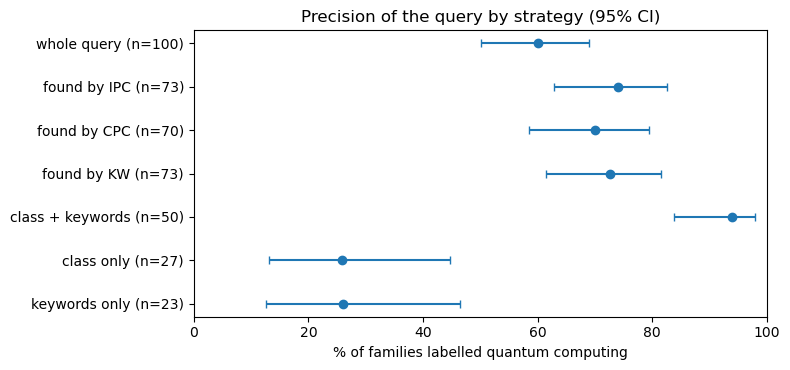

In [21]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half


res = sample.set_index("docdb_family_id").join(labels)
res["n_yes"] = res[names].sum(axis=1)
res["majority"] = (res["n_yes"] >= 2).astype(int)


def prec_row(label, flag):
    flag = flag.astype(int)
    k, n = int(flag.sum()), len(flag)
    lo, hi = wilson(k, n) if n else (np.nan, np.nan)
    return {"group": label, "sample": n, "QC (majority)": k, "precision": k / n if n else np.nan, "CI low": lo, "CI high": hi}


groups = [("whole query", res["majority"])]
groups += [(f"found by {s}", res.loc[res[s], "majority"]) for s in ("IPC", "CPC", "KW")]
groups += [(e, res.loc[res["evidence"] == e, "majority"]) for e in ("class + keywords", "class only", "keywords only")]
precision = pd.DataFrame([prec_row(g, s) for g, s in groups]).set_index("group")
display(precision.style.format({"precision": "{:.1%}", "CI low": "{:.1%}", "CI high": "{:.1%}"}))

bounds = pd.DataFrame([
    prec_row("majority (reference)", res["majority"]),
    prec_row("strict: all 3 say 1", res["n_yes"] == 3),
    prec_row("lenient: at least 1 says 1", res["n_yes"] >= 1),
    *[prec_row(f"{n} alone", res[n]) for n in names],
]).set_index("group")
display(bounds.style.format({"precision": "{:.1%}", "CI low": "{:.1%}", "CI high": "{:.1%}"}))

N_QUERY = len(pool)      # families with some text: the population the sample was drawn from
p = precision.loc["whole query"]
print(f"Estimated true QC families in the query: {p['precision'] * N_QUERY:,.0f} "
      f"(95% CI {p['CI low'] * N_QUERY:,.0f} - {p['CI high'] * N_QUERY:,.0f}) out of {N_QUERY:,}")

fig, ax = plt.subplots(figsize=(8, 3.8))
plot = precision.dropna()
ax.errorbar(plot["precision"] * 100, range(len(plot)),
            xerr=[(plot["precision"] - plot["CI low"]) * 100, (plot["CI high"] - plot["precision"]) * 100],
            fmt="o", capsize=3)
ax.set_yticks(range(len(plot)), [f"{g} (n={int(n)})" for g, n in zip(plot.index, plot["sample"])])
ax.invert_yaxis()
ax.set(title="Precision of the query by strategy (95% CI)", xlabel="% of families labelled quantum computing", xlim=(0, 100))
plt.tight_layout()
plt.show()

res.to_csv(VAL_DIR / "validation_result.csv")      # labels + evidence per sampled family (contains patent texts: not committed)

## 7. Extract

From the QC families, one extraction per table, in chunks of family ids:

| Table | What we take |
|---|---|
| `tls201_appln` | office, filing date, grant flag, family size, forward citations (`nb_citing_docdb_fam`) |
| `tls206_person` + `tls207_pers_appln` | applicants (`applt_seq_nr > 0`), PATSTAT/HAN names, sector, country |
| `tls211_pat_publn` + `tls212_citation` | backward citations (patents and non-patent literature) |
| `tls202` / `tls203` | title and abstract for the NLP steps (already extracted in section 6) |

In [22]:
chunks = [FAMILY_IDS[i:i + CHUNK] for i in range(0, len(FAMILY_IDS), CHUNK)]


def query_family_info(id_chunk):
    # one row per application: office, date, grant, family size, forward citations
    return (
        db.query(
            TLS201_APPLN.docdb_family_id,
            TLS201_APPLN.appln_auth,
            TLS201_APPLN.appln_filing_date,
            TLS201_APPLN.earliest_filing_year,
            TLS201_APPLN.granted,
            TLS201_APPLN.docdb_family_size,
            TLS201_APPLN.nb_citing_docdb_fam,
        )
        .filter(TLS201_APPLN.docdb_family_id.in_(id_chunk), TLS201_APPLN.ipr_type == IPR_TYPE)
        .distinct()
    )


def query_applicants(id_chunk):
    # applicants only (applt_seq_nr > 0): inventors are excluded
    return (
        db.query(
            TLS201_APPLN.docdb_family_id,
            TLS206_PERSON.person_id,
            TLS206_PERSON.person_name,      # raw name, last-resort fallback
            TLS206_PERSON.psn_id,
            TLS206_PERSON.psn_name,         # PATSTAT standardised name
            TLS206_PERSON.han_id,           # OECD HAN harmonised id/name (0 / empty = not available)
            TLS206_PERSON.han_name,
            TLS206_PERSON.psn_sector,       # COMPANY / UNIVERSITY / GOV NON-PROFIT / INDIVIDUAL ...
            func.trim(TLS206_PERSON.person_ctry_code).label("applicant_ctry"),
        )
        .select_from(TLS201_APPLN)
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(TLS201_APPLN.docdb_family_id.in_(id_chunk), TLS201_APPLN.ipr_type == IPR_TYPE, TLS207_PERS_APPLN.applt_seq_nr > 0)
        .distinct()
    )


def query_backward_citations(id_chunk, cited_col, label, is_cited):
    # number of distinct documents cited by the publications of the family
    # is_cited: condition that keeps only real citations (the "no citation" value differs by column type)
    return (
        db.query(TLS201_APPLN.docdb_family_id, func.count(distinct(cited_col)).label(label))
        .select_from(TLS201_APPLN)
        .join(TLS211_PAT_PUBLN, TLS211_PAT_PUBLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS212_CITATION, TLS212_CITATION.pat_publn_id == TLS211_PAT_PUBLN.pat_publn_id)
        .filter(TLS201_APPLN.docdb_family_id.in_(id_chunk), TLS201_APPLN.ipr_type == IPR_TYPE, is_cited)
        .group_by(TLS201_APPLN.docdb_family_id)
    )


def run(builder, *args):
    return pd.concat([patstat.df(builder(c, *args)) for c in chunks], ignore_index=True)


apps = run(query_family_info)
applicants = run(query_applicants)

# cited_pat_publn_id is INTEGER (0 = none) but cited_npl_publn_id is a STRING ("0" or empty = none)
pat_col, npl_col = TLS212_CITATION.cited_pat_publn_id, TLS212_CITATION.cited_npl_publn_id
bwd_patent = run(query_backward_citations, pat_col, "bwd_citations_patent", pat_col > 0)
bwd_npl = run(query_backward_citations, npl_col, "bwd_citations_npl",
              and_(npl_col.isnot(None), npl_col != "0", npl_col != ""))

print(f"applications: {len(apps):,} | applicant rows: {len(applicants):,} | texts: {len(texts_all):,}")

applications: 29,183 | applicant rows: 29,442 | texts: 12,833


## 8. Clean

- **Unit**: the DOCDB family (each invention counted once).
- **Time**: earliest filing year of the family (`earliest_filing_year`).
- **Truncation**: the last `TRUNCATION_YEARS` years are flagged (`truncated = True`), **not** dropped and **not** to be read as a decline. Check it on the yearly counts below.
- **Applicants**: HAN name when available, else PSN name; then normalisation of legal forms and a few explicit group rules for subsidiaries (extend `GROUP_RULES`, especially with the players relevant for Dell).

In [23]:
# ---- from applications to families ----
apps["appln_auth"] = apps["appln_auth"].astype("string").str.strip()
apps["granted"] = apps["granted"].astype(str).str.upper().isin(["Y", "1", "TRUE"])
apps["appln_filing_date"] = pd.to_datetime(apps["appln_filing_date"], errors="coerce")

first_filing = apps.sort_values("appln_filing_date").drop_duplicates("docdb_family_id").set_index("docdb_family_id")
families = apps.groupby("docdb_family_id").agg(
    family_year=("earliest_filing_year", "min"),
    offices=("appln_auth", lambda s: " ".join(sorted(set(s.dropna())))),
    n_offices=("appln_auth", "nunique"),
    granted_any=("granted", "any"),
    family_size=("docdb_family_size", "max"),
    fwd_citations=("nb_citing_docdb_fam", "max"),
)
families["first_office"] = first_filing["appln_auth"]
families = (
    families.join(bwd_patent.set_index("docdb_family_id"))
    .join(bwd_npl.set_index("docdb_family_id"))
    .join(membership[["IPC", "CPC", "KW", "evidence"]])
    .join(texts_all.set_index("docdb_family_id")[["appln_title", "appln_abstract"]])
)
families[["bwd_citations_patent", "bwd_citations_npl"]] = families[["bwd_citations_patent", "bwd_citations_npl"]].fillna(0).astype(int)

# ---- truncation flag ----
LAST_COMPLETE_YEAR = END_YEAR - TRUNCATION_YEARS
families["truncated"] = families["family_year"] > LAST_COMPLETE_YEAR

print(f"families: {len(families):,} | flagged as truncated (>{LAST_COMPLETE_YEAR}): {families['truncated'].mean():.1%}")
families.groupby("family_year").size().rename("families").to_frame().T   # look for the drop: is it where you flag it?

families: 12,833 | flagged as truncated (>2020): 57.6%


family_year,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
families,7,4,2,3,4,4,9,19,19,38,...,135,191,280,445,750,1124,1446,1924,2528,2940


In [24]:
# ---- applicants: harmonised names ----
# legal forms are removed for matching; the rules in GROUP_RULES are applied to the CLEANED name
LEGAL_FORMS = (
    r"\b(INCORPORATED|INC|CORPORATION|CORP|COMPANY|CO|LIMITED|LTD|LLC|LLP|LP|PLC|GMBH|AG|SA|SAS|SRL|SPA|BV|NV|AB|OY|"
    r"KK|KABUSHIKI KAISHA|PTE|PTY|HOLDINGS?|GROUP|THE)\b"
)

# explicit rules for groups and subsidiaries: first match wins (extend it, especially with Dell's competitors/partners)
GROUP_RULES = [
    (r"\bINTERNATIONAL BUSINESS MACHINES\b|^IBM\b",      "IBM"),
    (r"\bGOOGLE\b|\bALPHABET\b|\bX DEVELOPMENT\b",       "GOOGLE"),
    (r"\bMICROSOFT\b",                                   "MICROSOFT"),
    (r"\bD[- ]?WAVE\b",                                  "D-WAVE"),
    (r"\bRIGETTI\b",                                     "RIGETTI"),
    (r"\bIONQ\b",                                        "IONQ"),
    (r"\bINTEL\b",                                       "INTEL"),
    (r"\bHEWLETT PACKARD\b|^HP\b",                       "HEWLETT PACKARD"),
    (r"\bNORTHROP GRUMMAN\b",                            "NORTHROP GRUMMAN"),
    (r"\bTOSHIBA\b",                                     "TOSHIBA"),
    (r"\bHITACHI\b",                                     "HITACHI"),
    (r"\bNEC\b|\bNIPPON ELECTRIC\b",                     "NEC"),
    (r"\bFUJITSU\b",                                     "FUJITSU"),
    (r"\bTENCENT\b",                                     "TENCENT"),
    (r"\bALIBABA\b",                                     "ALIBABA"),
    (r"\bORIGIN QUANTUM\b",                              "ORIGIN QUANTUM"),   # "... HEFEI" and the parent were two groups
    (r"\bBAIDU\b",                                       "BAIDU"),
    (r"\bQUANTINUUM\b",                                  "QUANTINUUM"),
    (r"\bDELL\b|\bEMC IP\b",                             "DELL"),     # EMC IP Holding Company -> "EMC IP" after cleaning
]


def clean_name(name):
    s = re.sub(r"[^A-Z0-9& ]", " ", str(name).upper())
    s = re.sub(LEGAL_FORMS, " ", s)
    return re.sub(r"\s+", " ", s).strip()


def to_group(clean):
    for pattern, group in GROUP_RULES:
        if re.search(pattern, clean):
            return group
    return clean


# name: HAN name, else PSN name, else the raw person name
def first_non_empty(*cols):
    out = pd.Series("", index=applicants.index, dtype="object")
    for col in cols:
        v = applicants[col].fillna("").astype(str).str.strip()
        out = out.where(out != "", v)
    return out.replace("", "UNKNOWN")


n_persons_before = applicants["person_id"].nunique()
applicants["applicant_name"] = first_non_empty("han_name", "psn_name", "person_name")
applicants["applicant_clean"] = applicants["applicant_name"].map(clean_name).replace("", "UNKNOWN")
applicants["applicant_group"] = applicants["applicant_clean"].map(to_group)

# one applicant group once per family (psn_id can be 0 = not harmonised: it must NOT be used to deduplicate persons);
# fractional weight for co-applicants
applicants = applicants.drop_duplicates(["docdb_family_id", "applicant_group"])
applicants["n_applicants"] = applicants.groupby("docdb_family_id")["applicant_group"].transform("nunique")
applicants["frac_count"] = 1 / applicants["n_applicants"]

out = applicants.merge(families.reset_index(), on="docdb_family_id", how="left")

print(f"families with at least one applicant: {out['docdb_family_id'].nunique():,} / {len(families):,}")
print(f"distinct applicant groups: {out['applicant_group'].nunique():,} (distinct person_id before: {n_persons_before:,})")
print(f"share of applicant rows left as UNKNOWN: {(out['applicant_group'] == 'UNKNOWN').mean():.1%}")
out.groupby("applicant_group")["docdb_family_id"].nunique().sort_values(ascending=False).head(20)

families with at least one applicant: 12,799 / 12,833
distinct applicant groups: 4,803 (distinct person_id before: 9,144)
share of applicant rows left as UNKNOWN: 3.5%


applicant_group
ORIGIN QUANTUM                     1002
IBM                                 772
UNKNOWN                             652
BAIDU                               354
MICROSOFT                           254
GOOGLE                              244
FUJITSU                             230
D-WAVE                              214
IONQ                                173
INTEL                               166
RUBAN QUANTUM TECHNOLOGY            153
QUANTINUUM                          148
NEC                                 137
RED HAT                             124
TOSHIBA                             112
NIPPON TELEGR & TELEPH NTT           98
HITACHI                              96
TSINGHUA UNIVERSITY                  93
MASSACHUSETTS INSTITUTE OF TECH      91
BANK OF AMERICA                      91
Name: docdb_family_id, dtype: int64

In [25]:
# ---- save: inputs of Step 1 / Step 2 ----
families.reset_index().to_parquet(OUTPUT_DIR / f"qc_families_clean_{ENV}.parquet", index=False)
out.to_parquet(OUTPUT_DIR / f"qc_applicants_clean_{ENV}.parquet", index=False)
out.drop(columns=["appln_title", "appln_abstract"]).to_csv(OUTPUT_DIR / f"qc_applicants_clean_{ENV}.csv", index=False, encoding="utf-8")
print("saved in", OUTPUT_DIR.resolve())

saved in /home/jovyan/outputs/step0
